# Baseline 2 — Exp11 · Post-hoc Calibration Suite (NO TRAINING)

**Only the existing Exp09 and Exp10 ResNet-50 Stage 1 checkpoints are used.** This notebook re-runs inference on the **original development validation images only** and tests:

1. **Seen-pair calibration**: subtract γ from every training-seen candidate-pair score.
2. **Disease class-prior logit adjustment**: subtract τ × log(train-fit disease prior) from each disease logit.
3. **Small combined γ/τ grid**: exploratory check for possible improvement in both Seen and Unseen.

**Not performed:** model retraining, Stage 2, official test, candidate restriction to 333, any dataset re-splitting, or replacing existing checkpoints.

**Interpretation warning:** Parameters are swept and reported on the **same development validation set**. Even the largest HM is *exploratory* and should not be presented as independent held-out performance. Do not use the Official Test to tune γ or τ.

## 1. Preflight — correct local paths and GPU availability

Run All is safe **if `outputs/exp11_calibration/` does not exist** and both checkpoints exist. This notebook will not touch `outputs/exp09*` or `outputs/exp10/` beyond reading them. It uses one GPU model at a time and `num_workers=0` for reliable Windows inference.

In [1]:
from pathlib import Path
import gc, json, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from torchvision import transforms as T
from torchvision.transforms import InterpolationMode
from model_resnet50 import load_resnet50_checkpoint
from evaluate import (DPDDataset, MEAN, STD, validate_development_splits, make_candidates,
                      sha256_file)

PROJECT_DIR = Path.cwd()
SPLIT_DIR = PROJECT_DIR / 'splits_v2'
IMAGE_ROOT = PROJECT_DIR.parent / 'DPD_Small_dataset'
OUTPUT_ROOT = PROJECT_DIR / 'outputs'
OUT_DIR = OUTPUT_ROOT / 'exp11_calibration'
SOURCES = {
    'exp09': OUTPUT_ROOT / 'b2_resnet50_exp09_b1matched_seed42',
    'exp10': OUTPUT_ROOT / 'exp10',
}
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE = 16
INFERENCE_WORKERS = 0  # intentional: Windows notebook and short inference only
GAMMAS = [0.0, 0.25, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0]
TAUS = [0.0, 0.05, 0.10, 0.20, 0.35, 0.50, 0.75, 1.0]
COMBINED = [(1.0, 0.10), (2.0, 0.10), (1.0, 0.25),
            (2.0, 0.25), (1.0, 0.50), (2.0, 0.50)]  # (gamma, tau)

assert PROJECT_DIR.name.lower() == 'baseline2', f'Open Baseline2 folder in VS Code: {PROJECT_DIR}'
assert SPLIT_DIR.is_dir() and IMAGE_ROOT.is_dir(), 'Check dataset/splits paths'
assert not OUT_DIR.exists(), f'{OUT_DIR} already exists. Do not overwrite earlier results.'
assert DEVICE.type == 'cuda', 'This inference run expects the RTX 4050; do not silently switch to CPU.'
for key, path in SOURCES.items():
    assert (path / 'best_development.pt').is_file(), f'Missing {key} checkpoint: {path}'
    assert (path / 'validation_metrics.json').is_file(), f'Missing {key} validation metrics: {path}'
free_bytes, total_bytes = torch.cuda.mem_get_info()
print('GPU:', torch.cuda.get_device_name(0))
print(f'CUDA available VRAM: {free_bytes / 2**30:.2f} / {total_bytes / 2**30:.2f} GiB')
if free_bytes < 2.5 * 2**30:
    raise RuntimeError('Too little free VRAM for inference. Close previous GPU sessions before Run All.')
print('PREFLIGHT PASSED. No training will be performed.')

GPU: NVIDIA GeForce RTX 4050 Laptop GPU
CUDA available VRAM: 4.96 / 6.00 GiB
PREFLIGHT PASSED. No training will be performed.


## 2. Verify splits, source checkpoint metadata and priors

All priors are computed **only from `train_fit.csv`**, and the candidate space stays at 9,625 pairs. No official-test files are opened.

In [2]:
frames, split_report = validate_development_splits(SPLIT_DIR)
assert split_report['counts'] == {'train_fit':6905, 'val_seen':695, 'val_unseen':400}
CANDIDATES = make_candidates('all_pairs')
assert CANDIDATES.shape == (9625, 2)
pair_c = CANDIDATES[:, 0].numpy().astype(np.int64)
pair_d = CANDIDATES[:, 1].numpy().astype(np.int64)
train_pairs = set(map(tuple, frames['train_fit'][['crop_id','disease_id']].to_numpy().tolist()))
seen_mask = np.asarray([tuple(pair) in train_pairs for pair in CANDIDATES.tolist()], dtype=bool)
assert seen_mask.sum() == 313
counts = np.bincount(frames['train_fit']['disease_id'].to_numpy(dtype=np.int64), minlength=175)
assert (counts > 0).all() and int(counts.sum()) == 6905
log_disease_prior = np.log(counts / counts.sum()).astype(np.float32)

source_metadata={}
for name, directory in SOURCES.items():
    cfg = json.loads((directory / 'config.json').read_text(encoding='utf8'))
    params = cfg['config']
    assert params['backbone'] == 'resnet50' and params['pretrained_weights'] == 'IMAGENET1K_V2'
    assert params['image_size'] == 224 and params['candidate_mode'] == 'all_pairs'
    assert cfg['development_split']['sha256'] == split_report['sha256'], 'Mismatch of development splits'
    assert np.array_equal(np.asarray(cfg['candidate_pairs'],dtype=np.int64), CANDIDATES.numpy())
    assert params['interpolation'] == 'bilinear_resize_nearest_rotation'
    metrics = json.loads((directory / 'validation_metrics.json').read_text(encoding='utf8'))
    source_metadata[name] = {'params':params, 'metrics':metrics, 'directory':directory}
    print(f"{name}: best epoch={metrics['epoch']}, seen={metrics['seen']['composition_top1']:.2%}, "
          f"unseen={metrics['unseen']['composition_top1']:.2%}")
print(f'Validated split: 6905 / 695 / 400; disease classes={len(counts)}; seen pairs={seen_mask.sum()}; candidates={len(CANDIDATES)}')

exp09: best epoch=12, seen=72.95%, unseen=4.00%
exp10: best epoch=13, seen=73.24%, unseen=4.00%
Validated split: 6905 / 695 / 400; disease classes=175; seen pairs=313; candidates=9625


## 3. Inference ONCE per checkpoint; save raw logits

Use original B1-matched **bilinear Resize(256) → CenterCrop(224)**. Logits are cached in the Exp11 output directory, so sweeps do not repeat GPU inference. No model is fine-tuned.

In [3]:
def eval_transform():
    return T.Compose([
        T.Resize(256, interpolation=InterpolationMode.BILINEAR),
        T.CenterCrop(224), T.ToTensor(), T.Normalize(MEAN, STD)
    ])

@torch.inference_mode()
def export_logits(model, frame):
    dataset = DPDDataset(frame, IMAGE_ROOT, eval_transform())
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=INFERENCE_WORKERS, pin_memory=True)
    crop_logits, disease_logits, crop_ids, disease_ids, filenames = [], [], [], [], []
    model.eval()
    for batch in loader:
        images = batch['image'].to(DEVICE, non_blocking=True)
        with torch.autocast(device_type='cuda', enabled=True):
            output = model(images)
        crop_logits.append(output['crop_logits'].float().cpu().numpy())
        disease_logits.append(output['disease_logits'].float().cpu().numpy())
        crop_ids.extend(batch['crop'].numpy().tolist())
        disease_ids.extend(batch['disease'].numpy().tolist())
        filenames.extend(batch['filename'])
    cache = {
        'crop_logits':np.vstack(crop_logits).astype(np.float32),
        'disease_logits':np.vstack(disease_logits).astype(np.float32),
        'crop_ids':np.array(crop_ids,dtype=np.int64),
        'disease_ids':np.array(disease_ids,dtype=np.int64),
        'filenames':np.array(filenames,dtype=str),
    }
    assert len(cache['crop_ids']) == len(frame)
    assert cache['crop_logits'].shape == (len(frame), 55)
    assert cache['disease_logits'].shape == (len(frame), 175)
    assert np.array_equal(cache['crop_ids'], frame['crop_id'].to_numpy())
    assert np.array_equal(cache['disease_ids'], frame['disease_id'].to_numpy())
    assert np.array_equal(cache['filenames'], frame['filename'].astype(str).to_numpy())
    return cache

OUT_DIR.mkdir(parents=True, exist_ok=False)
(OUT_DIR / 'sweep_config.json').write_text(json.dumps({
    'gamma_grid':GAMMAS,'tau_grid':TAUS,'combined_gamma_tau':COMBINED,
    'sources':{k:str(v) for k,v in SOURCES.items()},
    'original_split_hashes':split_report['sha256'],
    'candidate_pairs':len(CANDIDATES), 'seen_pairs':int(seen_mask.sum()),
    'purpose':'exploratory development-only post-hoc calibration; no test or retraining',
},indent=2),encoding='utf-8')
raw_logits={}
for name, meta in source_metadata.items():
    print('Loading',name,'...')
    model, saved = load_resnet50_checkpoint(meta['directory'] / 'best_development.pt', DEVICE)
    assert saved['development_split']['sha256'] == split_report['sha256']
    assert saved['config']['experiment_id'] == meta['params']['experiment_id']
    raw_logits[name]={}
    for split in ('val_seen','val_unseen'):
        cache=export_logits(model, frames[split])
        raw_logits[name][split]=cache
        np.savez_compressed(OUT_DIR / f'{name}_{split}_raw_logits.npz', **cache)
        print(f'  {split}: {len(cache["filenames"])} images; saved raw logits')
    del model, saved
    gc.collect()
    torch.cuda.empty_cache()
print('Inference complete for Exp09 and Exp10. Training was NOT performed.')

Loading exp09 ...
  val_seen: 695 images; saved raw logits
  val_unseen: 400 images; saved raw logits
Loading exp10 ...
  val_seen: 695 images; saved raw logits
  val_unseen: 400 images; saved raw logits
Inference complete for Exp09 and Exp10. Training was NOT performed.


## 4. Synthetic tests and safe candidate scoring

For each image, pair score is `log P(c|x) + log P(d|x) − τ log π(d) − γ 1[(c,d) ∈ train-fit]`. For `τ=0, γ=0`, the prediction must match the original **Exp09/Exp10 validation metrics** before any tuning is interpreted.

In [4]:
def stable_log_softmax(logits):
    logits = np.asarray(logits, dtype=np.float32)
    mx = logits.max(axis=1,keepdims=True)
    return logits - mx - np.log(np.exp(logits - mx).sum(axis=1,keepdims=True))

def evaluate_setting(cache, gamma, tau, batch=64, with_preds=False):
    assert gamma >= 0 and tau >= 0
    crops, diseases = cache['crop_ids'], cache['disease_ids']
    cp = stable_log_softmax(cache['crop_logits'])
    dp = stable_log_softmax(cache['disease_logits'])
    adjusted_dp = dp - np.float32(tau) * log_disease_prior[None,:]
    disease_pred = adjusted_dp.argmax(axis=1)
    crop_pred = cp.argmax(axis=1)
    correct=0; correct_top5=0; predicted_seen=0
    pred_pair_c=[]; pred_pair_d=[]
    for i in range(0,len(crops),batch):
        j=min(i+batch,len(crops))
        # Chunk to limit peak RAM; candidate list identical to original all_pairs evaluation.
        scores=cp[i:j, pair_c] + adjusted_dp[i:j, pair_d]
        if gamma:
            scores[:, seen_mask] -= np.float32(gamma)
        best=scores.argmax(axis=1)
        rank5=np.argpartition(scores, kth=scores.shape[1]-5, axis=1)[:,-5:]
        true_pairs=crops[i:j] * 175 + diseases[i:j]
        # Canonical all_pairs catalogue index = crop_id*175 + disease_id.
        assert (pair_c[best] * 175 + pair_d[best]).shape == true_pairs.shape
        correct += int(np.sum(best == true_pairs))
        correct_top5 += int(np.sum((rank5 == true_pairs[:,None]).any(axis=1)))
        predicted_seen += int(seen_mask[best].sum())
        if with_preds:
            pred_pair_c.extend(pair_c[best].tolist())
            pred_pair_d.extend(pair_d[best].tolist())
    support = np.bincount(diseases, minlength=175)
    correct_by_dis=np.bincount(diseases, weights=(disease_pred==diseases).astype(int), minlength=175)
    macro_recall=float(np.mean(correct_by_dis[support>0] / support[support>0]))
    result=dict(n=len(crops),composition_top1=correct/len(crops),
                composition_top5=correct_top5/len(crops),
                crop_top1=float(np.mean(crop_pred==crops)),
                disease_top1=float(np.mean(disease_pred==diseases)),
                macro_disease_recall=macro_recall,
                predicted_pair_seen_rate=predicted_seen/len(crops),
                correct_count=correct)
    if with_preds:
        result['pred_pair_crop']=np.asarray(pred_pair_c,dtype=int)
        result['pred_pair_disease']=np.asarray(pred_pair_d,dtype=int)
        result['disease_pred']=disease_pred
    return result

# Synthetic smoke check: all-pair indexing, tau=gamma=0 baseline, and a strong seen-pair penalty.
artificial={'crop_logits':np.zeros((2,55),np.float32),
            'disease_logits':np.zeros((2,175),np.float32),
            'crop_ids':np.array([0,1]), 'disease_ids':np.array([0,0])}
artificial['crop_logits'][0,0]=5
artificial['crop_logits'][1,1]=5
artificial['disease_logits'][:,0]=5
assert evaluate_setting(artificial,0,0)['composition_top1'] == 1.0
assert 0 <= evaluate_setting(artificial,1,0)['composition_top1'] <= 1

for name in SOURCES:
    meta=source_metadata[name]['metrics']
    for split,key in [('val_seen','seen'),('val_unseen','unseen')]:
        score=evaluate_setting(raw_logits[name][split],0,0)
        expected=meta[key]['composition_top1']
        allowed=1/len(raw_logits[name][split]['crop_ids'])+1e-6
        print(f'{name} {split} baseline: {score["composition_top1"]:.4%} expected {expected:.4%}')
        assert abs(score['composition_top1']-expected) <= allowed, (
            'Baseline reproduction mismatch — investigate preprocessing, checkpoint or candidate scoring BEFORE sweeps')
print('BASELINE REPRODUCTION CHECK PASSED — safe to interpret exploratory sweeps.')

exp09 val_seen baseline: 72.9496% expected 72.9496%
exp09 val_unseen baseline: 4.0000% expected 4.0000%
exp10 val_seen baseline: 73.0935% expected 73.2374%
exp10 val_unseen baseline: 4.0000% expected 4.0000%
BASELINE REPRODUCTION CHECK PASSED — safe to interpret exploratory sweeps.


## 5. Run γ, τ, and small combined exploratory sweeps

This runs **CPU score calculations on cached logits**, not additional CNN training. `gamma=0,tau=0` is the control. Results are *exploratory*, not held-out final accuracy.

In [5]:
def harmonic_mean(a,b):
    return 0.0 if a+b == 0 else 2*a*b/(a+b)

settings=[('baseline',0.0,0.0)]
settings += [('seen_pair_gamma',float(g),0.0) for g in GAMMAS if g != 0]
settings += [('disease_prior_tau',0.0,float(t)) for t in TAUS if t != 0]
settings += [('combined',float(g),float(t)) for g,t in COMBINED]
results=[]
t0=time.perf_counter()
for source in SOURCES:
    for method,gamma,tau in settings:
        s=evaluate_setting(raw_logits[source]['val_seen'],gamma,tau)
        u=evaluate_setting(raw_logits[source]['val_unseen'],gamma,tau)
        results.append({
            'source':source,'method':method,'gamma':gamma,'tau':tau,
            'seen_composition':s['composition_top1'],
            'unseen_composition':u['composition_top1'],
            'composition_HM':harmonic_mean(s['composition_top1'],u['composition_top1']),
            'seen_top5':s['composition_top5'],'unseen_top5':u['composition_top5'],
            'seen_disease':s['disease_top1'], 'unseen_disease':u['disease_top1'],
            'unseen_disease_macro_recall':u['macro_disease_recall'],
            'unseen_crop':u['crop_top1'],
            'unseen_correct_of_400':u['correct_count'],
            'unseen_predicted_pair_seen_rate':u['predicted_pair_seen_rate'],
        })
    print(source,'calibrations completed')
sweep=pd.DataFrame(results)
for name in SOURCES:
    base=sweep[(sweep.source==name)&(sweep.method=='baseline')].iloc[0]
    idx=sweep.source==name
    sweep.loc[idx,'noninferior_seen_and_unseen']=(
        (sweep.loc[idx,'seen_composition']>=base.seen_composition) &
        (sweep.loc[idx,'unseen_composition']>=base.unseen_composition) &
        ((sweep.loc[idx,'seen_composition']>base.seen_composition)|
         (sweep.loc[idx,'unseen_composition']>base.unseen_composition)))
    sweep.loc[idx,'both_strictly_improve']=(
        (sweep.loc[idx,'seen_composition']>base.seen_composition) &
        (sweep.loc[idx,'unseen_composition']>base.unseen_composition))
sweep.to_csv(OUT_DIR/'calibration_sweep.csv',index=False)
print(f'Finished {len(sweep)} evaluations in {time.perf_counter()-t0:.1f}s')
cols=['source','method','gamma','tau','seen_composition','unseen_composition',
      'composition_HM','unseen_disease','unseen_correct_of_400','both_strictly_improve']
print('TOP DEVELOPMENT HM SETTINGS (not independent test results):')
display(sweep.sort_values('composition_HM',ascending=False)[cols].head(12))
print('SETTINGS THAT IMPROVE BOTH SEEN AND UNSEEN VS SAME MODEL BASELINE:')
display(sweep[sweep.both_strictly_improve][cols].sort_values('composition_HM',ascending=False))

exp09 calibrations completed
exp10 calibrations completed
Finished 44 evaluations in 4.3s
TOP DEVELOPMENT HM SETTINGS (not independent test results):


,source,method,gamma,tau,seen_composition,unseen_composition,composition_HM,unseen_disease,unseen_correct_of_400,both_strictly_improve
30,exp10,seen_pair_gamma,6.0,0.00,0.463309,0.0825,0.140060,0.2325,33,False
29,exp10,seen_pair_gamma,4.0,0.00,0.594245,0.0725,0.129233,0.2325,29,False
28,exp10,seen_pair_gamma,3.0,0.00,0.640288,0.0650,0.118019,0.2325,26,False
8,exp09,seen_pair_gamma,6.0,0.00,0.460432,0.0675,0.117739,0.2200,27,False
43,exp10,combined,2.0,0.50,0.656115,0.0625,0.114128,0.2225,25,False
7,exp09,seen_pair_gamma,4.0,0.00,0.601439,0.0625,0.113233,0.2200,25,False
39,exp10,combined,2.0,0.10,0.680576,0.0575,0.106041,0.2325,23,False
41,exp10,combined,2.0,0.25,0.671942,0.0575,0.105935,0.2300,23,False
27,exp10,seen_pair_gamma,2.0,0.00,0.682014,0.0550,0.101791,0.2325,22,False
6,exp09,seen_pair_gamma,3.0,0.00,0.646043,0.0550,0.101370,0.2200,22,False


SETTINGS THAT IMPROVE BOTH SEEN AND UNSEEN VS SAME MODEL BASELINE:


,source,method,gamma,tau,seen_composition,unseen_composition,composition_HM,unseen_disease,unseen_correct_of_400,both_strictly_improve


## 6. Visualise seen/unseen trade-offs + save leader summary

The charts and summary explicitly distinguish *baseline*, *best development HM* and **strict Pareto improvements**. Any chosen calibration must be locked before independent final assessment.

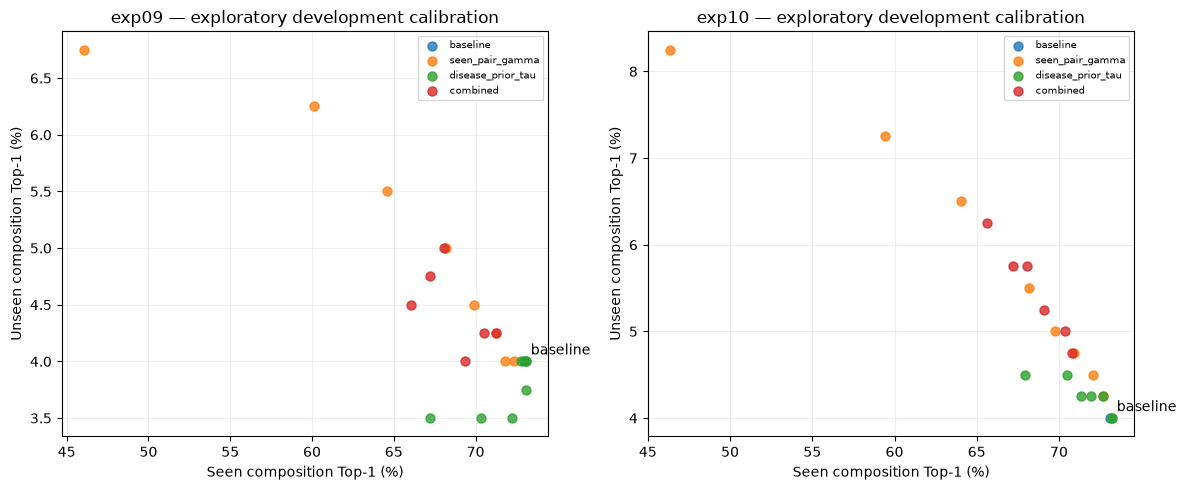

,source,best_gamma,best_tau,best_method,baseline_seen,baseline_unseen,baseline_HM,best_dev_seen,best_dev_unseen,best_dev_HM,both_improvement_found,both_best_gamma,both_best_tau,both_best_seen,both_best_unseen
0,exp09,6.0,0.0,seen_pair_gamma,0.729496,0.04,0.075841,0.460432,0.0675,0.117739,False,NaN,NaN,NaN,NaN
1,exp10,6.0,0.0,seen_pair_gamma,0.730935,0.04,0.075849,0.463309,0.0825,0.140060,False,NaN,NaN,NaN,NaN


SUCCESS: calibration completed; outputs in: c:\AML\ML_Project\Baseline2\outputs\exp11_calibration
No training or official-test evaluation was executed.


In [6]:
fig, axes=plt.subplots(1,2,figsize=(12,5))
for ax,source in zip(axes, SOURCES):
    tab=sweep[sweep.source==source]
    for group, grp in tab.groupby('method',sort=False):
        ax.scatter(grp.seen_composition*100,grp.unseen_composition*100,
                   label=group,alpha=.8,s=42)
    baseline=tab[tab.method=='baseline'].iloc[0]
    ax.annotate('baseline', (baseline.seen_composition*100,baseline.unseen_composition*100),xytext=(5,5),textcoords='offset points')
    ax.set(xlabel='Seen composition Top-1 (%)',ylabel='Unseen composition Top-1 (%)',
           title=f'{source} — exploratory development calibration')
    ax.grid(alpha=.2)
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUT_DIR/'seen_unseen_calibration_tradeoff.png',dpi=160)
plt.show()

rows=[]
for source in SOURCES:
    group=sweep[sweep.source==source]
    base=group[group.method=='baseline'].iloc[0]
    top=group.sort_values(['composition_HM','seen_composition'],ascending=False).iloc[0]
    both=group[group.both_strictly_improve].sort_values('composition_HM',ascending=False)
    rows.append({'source':source,'best_gamma':top.gamma,'best_tau':top.tau,
                 'best_method':top.method,'baseline_seen':base.seen_composition,
                 'baseline_unseen':base.unseen_composition,'baseline_HM':base.composition_HM,
                 'best_dev_seen':top.seen_composition,'best_dev_unseen':top.unseen_composition,
                 'best_dev_HM':top.composition_HM,
                 'both_improvement_found':bool(len(both)),
                 'both_best_gamma':both.iloc[0].gamma if len(both) else np.nan,
                 'both_best_tau':both.iloc[0].tau if len(both) else np.nan,
                 'both_best_seen':both.iloc[0].seen_composition if len(both) else np.nan,
                 'both_best_unseen':both.iloc[0].unseen_composition if len(both) else np.nan})
summary=pd.DataFrame(rows)
summary.to_csv(OUT_DIR/'calibration_summary.csv',index=False)
display(summary)

def fmt(row):
    return f"Seen {row.seen_composition:.2%} / Unseen {row.unseen_composition:.2%} / HM {row.composition_HM:.2%} ({row.unseen_correct_of_400}/400)"
lines=['# Exp11 — Post-hoc Calibration Findings (DEVELOPMENT ONLY)','',
       '**Scope:** Exp09 & Exp10 ResNet-50 V2 stage-1 checkpoints, original fixed development splits, all 9,625 candidates. No retraining, Stage 2 or Official Test.',
       '**Important:** hyperparameters were swept on the same development validation images used to report results; peak development scores are exploratory and may be optimistic.',
       '', '## Main findings']
for source in SOURCES:
    group=sweep[sweep.source==source]
    base=group[group.method=='baseline'].iloc[0]
    top=group.sort_values('composition_HM',ascending=False).iloc[0]
    both=group[group.both_strictly_improve].sort_values('composition_HM',ascending=False)
    lines += [f'### {source}',f'- Baseline: {fmt(base)}',
              f'- Highest measured development HM: {fmt(top)} at method={top.method}, γ={top.gamma:g}, τ={top.tau:g}.',
              f'- Strict Seen+Unseen improvement found in measured grid: **{"YES" if len(both) else "NO"}**.']
    if len(both):
        bestboth=both.iloc[0]
        lines.append(f'- Highest-HM strict Pareto result: {fmt(bestboth)} at γ={bestboth.gamma:g}, τ={bestboth.tau:g}.')
    lines.append('')
lines += ['## Methods and interpretation',
          '- Uniform seen-pair penalty γ >= 0 is a trade-off: it cannot increase seen Top-1 for a fixed set of raw scores; use the full seen-unseen curve.',
          '- Disease logit adjustment uses π(d) from training-fit ONLY and applies z_d - τ log π(d). This may improve minority disease recall but can hurt healthy/common classes.',
          '- The combined γ/τ grid is exploratory and limited; it is not a hyperparameter guarantee.',
          '- Do not infer generalisation beyond these ten held-out development compositions without independent assessment.',
          '- Candidate restriction to 333 was NOT tested. Multi-seed re-training was NOT performed.',
          '', '## Files',
          '- calibration_sweep.csv: full evaluated settings, including disease and macro disease recall.',
          '- calibration_summary.csv: control and highest measured development-HM settings.',
          '- seen_unseen_calibration_tradeoff.png: trade-off scatter plot.',
          '- exp09/exp10 development raw logits: NPZ files in this directory.',
          '', '## References (background, not claims of implementation)',
          '- Chao et al. (2016), An Empirical Study and Analysis of Generalized Zero-Shot Learning for Object Recognition in the Wild.',
          '- Menon et al. (2021), Long-Tail Learning via Logit Adjustment.']
(OUT_DIR/'leader_calibration_summary.md').write_text('\n'.join(lines)+'\n',encoding='utf8')
print('SUCCESS: calibration completed; outputs in:',OUT_DIR)
print('No training or official-test evaluation was executed.')

## 7. Next experiments — deliberately NOT executed

If disease-prior adjustment improves Seen and Unseen on development, **report it as an exploratory result first**. Before making a final performance claim, freeze parameters and use a group-approved independent validation / evaluation protocol.

If calibration only trades Seen for Unseen, consider: (a) macro-balanced disease loss, (b) a separate sampling α=0.5 experiment, or (c) carefully controlled multi-seed repeats of Exp09/Exp10. Those require new training runs and are **not launched by this notebook**.

**Checkpoint and audit notes:** Exp09/Exp10 remain immutable; Exp11 is inference-only. Calibration has an empirical/theoretical basis but cannot guarantee that both Seen and Unseen accuracy increase.

In [7]:

original = pd.read_csv(
    OUTPUT_ROOT / "exp10" / "val_seen_error_predictions.csv"
)

cache = raw_logits["exp10"]["val_seen"]
recalculated = evaluate_setting(
    cache, gamma=0, tau=0, with_preds=True
)

new = pd.DataFrame({
    "filename": cache["filenames"],
    "new_crop": recalculated["pred_pair_crop"],
    "new_disease": recalculated["pred_pair_disease"]
})

merged = original.merge(
    new, on="filename", validate="one_to_one"
)

different = merged[
    (merged.predicted_pair_crop_id != merged.new_crop) |
    (merged.predicted_pair_disease_id != merged.new_disease)
]

print("Different predictions:", len(different))
display(different)


Different predictions: 1


,filename,crop_id,disease_id,composition_id,predicted_crop_id,predicted_disease_id,predicted_pair_crop_id,predicted_pair_disease_id,ranked_crop_ids,ranked_disease_ids,ranked_composition_pairs,crop_correct,disease_correct,crop_only_wrong,disease_only_wrong,both_wrong,predicted_pair_seen_in_training,new_crop,new_disease
562,PWV2_grape_downy_mildew_5468.jpg,27,28,145,27,28,27,28,"[27, 35, 0, 22, 51]","[28, 10, 33, 139, 41]","[[27, 28], [27, 10], [27, 33], [27, 139], [27,...",True,True,False,False,False,True,27,10


In [8]:

from evaluate import composition_scores

cache = raw_logits["exp10"]["val_seen"]

filename = "PWV2_grape_downy_mildew_5468.jpg"
idx = np.where(cache["filenames"] == filename)[0]

assert len(idx) == 1
i = int(idx[0])

z = cache["disease_logits"][i]

print("Disease 28 (downy_mildew):", z[28])
print("Disease 10 (rust):", z[10])
print("Logit difference:", float(z[28]) - float(z[10]))
print("Exactly equal:", bool(z[28] == z[10]))

# Reproduce original PyTorch composition scoring
c = torch.tensor(
    cache["crop_logits"][i:i+1], device=DEVICE
)
d = torch.tensor(
    cache["disease_logits"][i:i+1], device=DEVICE
)

scores = composition_scores(
    c, d, CANDIDATES.to(DEVICE)
)

top5 = scores.topk(5, dim=1).indices[0].cpu()

print("PyTorch Top-5 pairs:")
print(CANDIDATES[top5].tolist())

score_true = scores[0, 27 * 175 + 28].item()
score_rust = scores[0, 27 * 175 + 10].item()

print("True pair score:", score_true)
print("Rust pair score:", score_rust)
print("Score difference:", score_true - score_rust)


Disease 28 (downy_mildew): -12.25
Disease 10 (rust): -12.25
Logit difference: 0.0
Exactly equal: True
PyTorch Top-5 pairs:
[[27, 28], [27, 10], [27, 33], [27, 139], [27, 41]]
True pair score: -1.5340172052383423
Rust pair score: -1.5340172052383423
Score difference: 0.0
